# 01 · Neural-network building blocks
### From Week 1's hand-made kernels to *learned* kernels

**Covers (Week 3 Key Concepts):** fully connected vs convolutional layers · ReLU · Dropout · pooling · how a network learns.
**Questions answered here:** Easy 5–7 · Hard 1–2 · Week-1 Q "role of kernels in CNNs".

Everything later this week (LeNet, ResNet, YOLO, U-Net, LSTMs, ViT) is built from the few pieces in this notebook. Run each cell with **Shift + Enter** and read the text around it.

> **The one-sentence version:** a CNN is a stack of Week-1 convolutions, but instead of a human choosing the kernel numbers (like Sobel), **the computer learns them from examples**.

## 0 · Setup
Install once, from a terminal: `pip install torch torchvision scikit-learn matplotlib opencv-python`.
On Google Colab everything is already installed.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2

torch.manual_seed(0)
np.random.seed(0)
print("torch", torch.__version__, "| GPU available:", torch.cuda.is_available())

torch 2.14.1+cu130 | GPU available: False


## 1 · A convolution layer *is* Week-1 convolution

PyTorch's `nn.Conv2d` slides kernels over an image exactly like `cv2.filter2D`. To prove it, we create a conv layer, **paste the Sobel-X kernel into its weights by hand**, and compare it with OpenCV.

- `nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, padding=1, bias=False)` means 1 input channel (grayscale) and 1 kernel of size 3×3. `padding=1` keeps the output the same size, like OpenCV's border handling.
- PyTorch images are shaped **(batch, channels, height, width)**, unlike OpenCV's (height, width, channels).

In [2]:
# A small test image: dark left half, bright right half -> one vertical edge
img = np.zeros((8, 8), np.float32)
img[:, 4:] = 200

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], np.float32)

conv = nn.Conv2d(1, 1, kernel_size=3, padding=1, bias=False)
with torch.no_grad():
    conv.weight[:] = torch.from_numpy(sobel_x)          # paste Sobel into the layer

x = torch.from_numpy(img)[None, None]                   # (8,8) -> (1,1,8,8) = (batch, channel, H, W)
torch_out = conv(x)[0, 0].detach().numpy()
cv_out = cv2.filter2D(img, -1, sobel_x, borderType=cv2.BORDER_CONSTANT)

print("PyTorch conv layer output (row 0):", torch_out[0])
print("OpenCV filter2D output    (row 0):", cv_out[0])
print("Same result?", np.allclose(torch_out, cv_out))

PyTorch conv layer output (row 0): [   0.    0.    0.  600.  600.    0.    0. -600.]
OpenCV filter2D output    (row 0): [   0.    0.    0.  600.  600.    0.    0. -600.]
Same result? True


**Same numbers.** The only difference in a real CNN is that the 9 kernel numbers start **random** and are adjusted during training until they become useful detectors. A CNN layer also has **many** kernels (e.g. 64), each producing its own **feature map**.

## 2 · Fully connected (dense) layer vs convolutional layer

| | Fully connected (`nn.Linear`) | Convolutional (`nn.Conv2d`) |
|---|---|---|
| Connects to | **every** input value | a small **local** patch (receptive field) |
| Input | a **flat vector** (spatial layout lost) | an **image** (H × W × C kept) |
| Weights | different for every position | the **same kernel reused everywhere** (weight sharing) |
| Good at | combining everything for the final decision | finding local patterns: edges, textures, shapes |
| Parameters | **huge** | **few** |

Let's **count the parameters** (the learnable numbers) for a small 32×32 colour image:

In [3]:
def n_params(layer):
    return sum(p.numel() for p in layer.parameters())

fc = nn.Linear(32 * 32 * 3, 100)                   # 3072 inputs -> 100 neurons
cv = nn.Conv2d(3, 100, kernel_size=3, padding=1)   # 100 kernels of size 3x3x3

print(f"Fully connected: {n_params(fc):>9,} parameters  (each neuron sees all 3,072 pixel values)")
print(f"Convolutional  : {n_params(cv):>9,} parameters  (each kernel is just 3x3x3 = 27 weights + 1 bias)")
print(f"-> the FC layer needs {n_params(fc) / n_params(cv):.0f}x more parameters")

big_fc = 224 * 224 * 3 * 1000
print(f"\nFor a 224x224 photo, an FC layer of 1000 neurons would need {big_fc / 1e6:.0f} million weights!")

Fully connected:   307,300 parameters  (each neuron sees all 3,072 pixel values)
Convolutional  :     2,800 parameters  (each kernel is just 3x3x3 = 27 weights + 1 bias)
-> the FC layer needs 110x more parameters

For a 224x224 photo, an FC layer of 1000 neurons would need 151 million weights!


### Translation invariance: "find the pattern wherever it is"

Because the **same** kernel slides over every position, a pattern produces the **same response wherever it appears**: move the pattern and the response moves with it. A fully connected layer has separate weights per pixel, so a moved pattern looks like a completely different input.

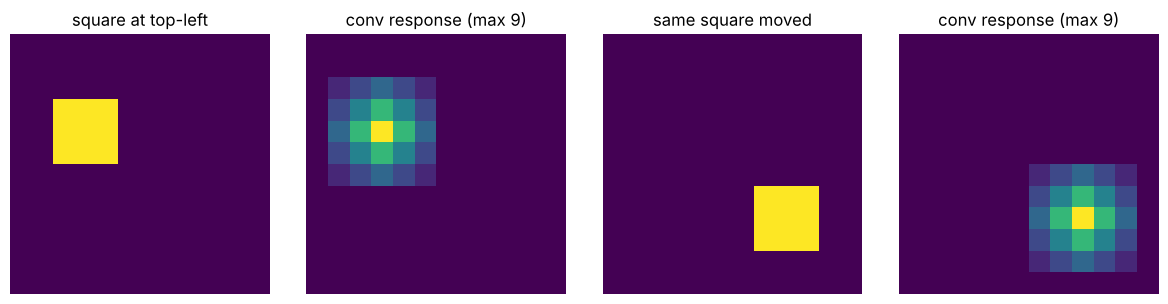

Strongest response is identical: True - it just moved along with the square.


In [4]:
pattern = np.zeros((12, 12), np.float32); pattern[3:6, 2:5] = 1          # a small square, top-left
moved = np.zeros((12, 12), np.float32);   moved[7:10, 7:10] = 1          # same square, bottom-right

with torch.no_grad():
    k = nn.Conv2d(1, 1, 3, padding=1, bias=False)
    k.weight[:] = 1.0                                                     # a simple "blob detector"
    r1 = k(torch.from_numpy(pattern)[None, None])[0, 0].numpy()
    r2 = k(torch.from_numpy(moved)[None, None])[0, 0].numpy()

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a, im, t in zip(ax, [pattern, r1, moved, r2],
                    ["square at top-left", f"conv response (max {r1.max():.0f})",
                     "same square moved", f"conv response (max {r2.max():.0f})"]):
    a.imshow(im, cmap="viridis"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()
print("Strongest response is identical:", r1.max() == r2.max(), "- it just moved along with the square.")

**In practice** CNNs use **convolutional layers for feature extraction** and **fully connected layers at the end for the decision** ("this is a 7"). You'll see that shape in LeNet, AlexNet and VGG in notebook 02.

## 3 · Activation functions: why ReLU won

Without an activation function, stacking layers is pointless: a linear layer followed by another linear layer is still just one linear layer. **Activations add non-linearity**, so networks can learn curved, complex patterns.

| Function | Formula | Output range |
|---|---|---|
| Sigmoid | 1 / (1 + e⁻ˣ) | 0 to 1 |
| Tanh | (eˣ − e⁻ˣ)/(eˣ + e⁻ˣ) | −1 to 1 |
| **ReLU** | **max(0, x)** | 0 to ∞ |

**ReLU: "if the input is positive, keep it; if negative, output zero."** It's like a filter that only lets positive signals through.

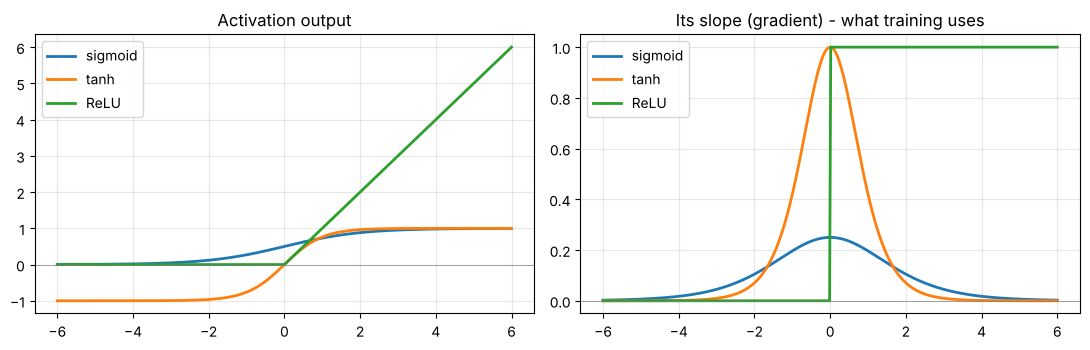

ReLU on [-3, -1, 0, 2, 5] -> [0.0, 0.0, 0.0, 2.0, 5.0]


In [5]:
x = torch.linspace(-6, 6, 400, requires_grad=True)
funcs = {"sigmoid": torch.sigmoid, "tanh": torch.tanh, "ReLU": torch.relu}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, f in funcs.items():
    y = f(x)
    grad, = torch.autograd.grad(y.sum(), x)          # the slope (derivative) at every x
    ax[0].plot(x.detach(), y.detach(), label=name, lw=2)
    ax[1].plot(x.detach(), grad, label=name, lw=2)
ax[0].set_title("Activation output"); ax[1].set_title("Its slope (gradient) - what training uses")
for a in ax:
    a.axhline(0, color="gray", lw=0.5); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("ReLU on [-3, -1, 0, 2, 5] ->", torch.relu(torch.tensor([-3., -1., 0., 2., 5.])).tolist())

Look at the **right plot**:
- **Sigmoid's slope is never more than 0.25**, and it's almost 0 for big or small inputs ("saturation"). Tanh's slope also dies at the ends.
- **ReLU's slope is exactly 1 for every positive input.**

### Why that matters: the vanishing gradient problem
Training works by **backpropagation**. The error signal travels backwards through the layers and gets **multiplied by each layer's slope** on the way. Multiply by ≤ 0.25 again and again and the signal **shrinks to almost nothing**, so the early layers stop learning. With ReLU, positive paths multiply by 1, so the signal survives.

Best-case gradient left after N layers (sigmoid slope <= 0.25, ReLU slope = 1):

   1 layers: sigmoid 2.50e-01   ReLU 1
   2 layers: sigmoid 6.25e-02   ReLU 1
   5 layers: sigmoid 9.77e-04   ReLU 1
  10 layers: sigmoid 9.54e-07   ReLU 1
  20 layers: sigmoid 9.09e-13   ReLU 1


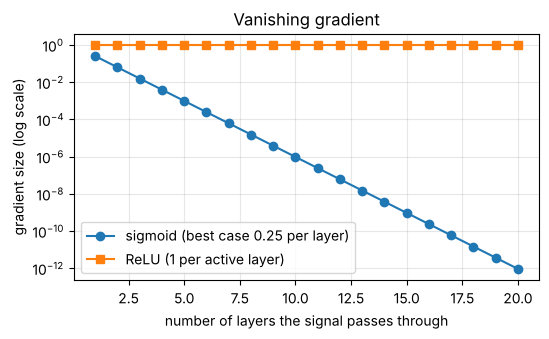

In [6]:
layers = np.arange(1, 21)
print("Best-case gradient left after N layers (sigmoid slope <= 0.25, ReLU slope = 1):\n")
for n in [1, 2, 5, 10, 20]:
    print(f"  {n:>2} layers: sigmoid {0.25 ** n:.2e}   ReLU {1.0 ** n:.0f}")

plt.figure(figsize=(6, 3.2))
plt.semilogy(layers, 0.25 ** layers, "o-", label="sigmoid (best case 0.25 per layer)")
plt.semilogy(layers, np.ones_like(layers, dtype=float), "s-", label="ReLU (1 per active layer)")
plt.xlabel("number of layers the signal passes through"); plt.ylabel("gradient size (log scale)")
plt.title("Vanishing gradient"); plt.legend(); plt.grid(alpha=0.3); plt.show()

After only 10 sigmoid layers the gradient is a **millionth** of its size. This is one of the reasons **AlexNet (2012)** switched to ReLU: it trained about **6× faster** than tanh in the original paper, and deeper networks became practical.

> Exam phrasing: *ReLU introduces non-linearity, is cheap to compute (just max(0, x)), and its gradient is 1 for positive inputs, so it reduces the vanishing-gradient problem.* One caveat: neurons stuck at negative inputs output 0 forever (the "dying ReLU" problem). Variants such as Leaky ReLU fix this.

## 4 · Dropout: randomly benching neurons during training

**Definition:** a **regularization** technique (a way to prevent **overfitting**, i.e. memorising the training data instead of learning general rules).
**How:** during each **training** step, each neuron is switched off (set to 0) with probability *p*. A different random set is dropped each time.
**Analogy:** a team where random members sit out each practice, so everyone has to learn to contribute and nobody becomes a single point of failure.

The Key Concepts example: *a layer has 10 neurons and dropout rate 0.3, so about 3 are ignored in each training pass.*

In [7]:
drop = nn.Dropout(p=0.3)
activations = torch.ones(10)                        # 10 neurons, all outputting 1.0

drop.train()                                        # TRAINING mode: dropout is active
for step in range(3):
    out = drop(activations)
    print(f"training pass {step + 1}: {np.round(out.numpy(), 2)}  -> {int((out == 0).sum())} dropped")

drop.eval()                                         # EVALUATION / test mode: dropout switched OFF
print("\ntest time      :", drop(activations).numpy())

training pass 1: [1.43 1.43 0.   1.43 1.43 1.43 1.43 1.43 1.43 1.43]  -> 1 dropped
training pass 2: [1.43 1.43 0.   1.43 1.43 1.43 1.43 1.43 0.   0.  ]  -> 3 dropped
training pass 3: [1.43 1.43 1.43 0.   0.   1.43 0.   1.43 1.43 1.43]  -> 3 dropped

test time      : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Two details worth knowing:
1. The surviving neurons are **scaled up by 1/(1 − p)** (here 1/0.7 ≈ 1.43). This keeps the *average* signal the same as at test time.
2. Dropout is **only active during training**. `model.train()` turns it on and `model.eval()` turns it off. Forgetting `model.eval()` before testing is a classic bug.

**Why it generalises better (Hard Q1):** the network can't rely on one specific neuron ("the neuron that detects *this exact* cat photo's ear"), because that neuron may be missing. It has to spread knowledge across many neurons and learn **robust features** that work even with parts missing. That's exactly what's needed on new, unseen images. Below we test it on a deliberately overfitting-prone setup.

In [8]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()                                       # 1,797 handwritten digits, 8x8 pixels, ships with sklearn
X = torch.tensor(digits.data, dtype=torch.float32) / 16.0    # pixel values 0..16 -> 0..1
y = torch.tensor(digits.target)

def train_and_test(p_drop, seed, n_train=60, epochs=500):
    # a BIG network + only 60 training images = a recipe for overfitting
    Xtr, Xte, ytr, yte = train_test_split(X, y, train_size=n_train, random_state=seed, stratify=y)
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Linear(64, 1024), nn.ReLU(), nn.Dropout(p_drop),
                          nn.Linear(1024, 1024), nn.ReLU(), nn.Dropout(p_drop),
                          nn.Linear(1024, 10))
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(epochs):
        model.train()                                        # dropout ON
        loss = F.cross_entropy(model(Xtr), ytr)
        opt.zero_grad(); loss.backward(); opt.step()
    model.eval()                                             # dropout OFF for testing
    with torch.no_grad():
        train_acc = (model(Xtr).argmax(1) == ytr).float().mean().item()
        test_acc = (model(Xte).argmax(1) == yte).float().mean().item()
    return train_acc, test_acc

# Results vary from run to run, so average 5 runs (different data splits and starting weights)
for p in [0.0, 0.5]:
    runs = [train_and_test(p, seed) for seed in range(5)]
    tr = np.mean([r[0] for r in runs]); te = np.mean([r[1] for r in runs])
    print(f"dropout p={p}: train accuracy {tr:.1%}   test accuracy (unseen) {te:.1%}")

dropout p=0.0: train accuracy 100.0%   test accuracy (unseen) 86.7%


dropout p=0.5: train accuracy 100.0%   test accuracy (unseen) 87.8%


Both versions score **100% on the 60 training images**: they have memorised them. On the ~1,700 **unseen** images, the dropout version does slightly but consistently better. The gap between training and test accuracy *is* overfitting, and dropout narrows it.

The gain here is small (about 1 percentage point) because this problem is tiny. Dropout matters most in **huge** layers. AlexNet's fully connected layers held about 58 million weights, and the paper reports that without dropout the network overfitted badly.

## 5 · Pooling: shrinking feature maps

CNNs (LeNet, AlexNet, VGG) alternate **conv → ReLU → pool**.
**Max pooling 2×2** keeps the biggest value in each 2×2 block:
- it halves the height and width, which means less computation for the next layer,
- it keeps "was the pattern present somewhere around here?", and
- it adds a little tolerance to small shifts.

It has no learnable parameters.

In [9]:
fm = torch.tensor([[1., 3, 2, 0],
                   [4, 6, 1, 1],
                   [0, 2, 9, 5],
                   [1, 1, 3, 7]])
print("feature map (4x4):\n", fm.int().numpy())
print("\nafter 2x2 max pooling (2x2):\n", F.max_pool2d(fm[None, None], 2)[0, 0].int().numpy())
print("\nafter 2x2 average pooling:\n", F.avg_pool2d(fm[None, None], 2)[0, 0].numpy())

feature map (4x4):
 [[1 3 2 0]
 [4 6 1 1]
 [0 2 9 5]
 [1 1 3 7]]

after 2x2 max pooling (2x2):
 [[6 2]
 [2 9]]

after 2x2 average pooling:
 [[3.5 1. ]
 [1.  6. ]]


## 6 · How a network learns: the training loop

Every model in this course is trained with the same 4-step loop, repeated thousands of times:

1. **Forward pass:** push images through the network to get predictions.
2. **Loss:** one number for "how wrong were we?" (cross-entropy for classification).
3. **Backward pass:** `loss.backward()` computes the **gradient**, i.e. which way to nudge every weight to reduce the loss. This is backpropagation.
4. **Step:** the optimizer (SGD or Adam) nudges all the weights a little.

Below is a tiny CNN learning the 8×8 digits. Watch the loss fall, and compare the first layer's kernels before and after training: every number has been adjusted by the loop.

test accuracy after 60 steps: 96.1%  (random guessing = 10%)


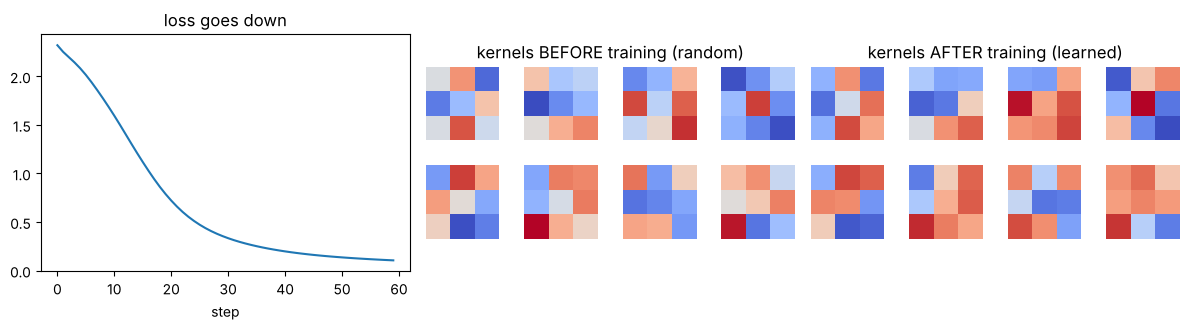

In [10]:
Xtr_img, Xte_img, ytr_d, yte_d = train_test_split(X.reshape(-1, 1, 8, 8), y, test_size=0.3, random_state=0, stratify=y)

torch.manual_seed(0)
tiny_cnn = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 8 learned 3x3 kernels -> 8 maps of 4x4
    nn.Flatten(), nn.Linear(8 * 4 * 4, 10))                                  # FC layer makes the decision
first_kernels_before = tiny_cnn[0].weight.detach().clone()

opt = torch.optim.Adam(tiny_cnn.parameters(), lr=0.01)
losses = []
for epoch in range(60):
    logits = tiny_cnn(Xtr_img)                 # 1. forward
    loss = F.cross_entropy(logits, ytr_d)      # 2. loss
    opt.zero_grad(); loss.backward()           # 3. backward (gradients)
    opt.step()                                 # 4. update weights
    losses.append(loss.item())

with torch.no_grad():
    acc = (tiny_cnn(Xte_img).argmax(1) == yte_d).float().mean().item()
print(f"test accuracy after 60 steps: {acc:.1%}  (random guessing = 10%)")

fig = plt.figure(figsize=(12, 3.4))
ax = fig.add_subplot(1, 3, 1); ax.plot(losses); ax.set_title("loss goes down"); ax.set_xlabel("step")
for row, (w, title) in enumerate([(first_kernels_before, "kernels BEFORE training (random)"),
                                  (tiny_cnn[0].weight.detach(), "kernels AFTER training (learned)")]):
    sub = fig.add_subplot(1, 3, row + 2); sub.set_title(title); sub.axis("off")
    tiles = np.full((7, 15), np.nan)
    for i in range(8):
        r, c = divmod(i, 4)
        tiles[r * 4:r * 4 + 3, c * 4:c * 4 + 3] = w[i, 0].numpy()
    sub.imshow(tiles, cmap="coolwarm")
plt.tight_layout(); plt.show()

The learned kernels changed, but on 8×8 images with only 3×3 kernels they're hard to interpret by eye. Notebook 02 trains LeNet on bigger images, where the learned filters and their feature maps are much easier to read.

That is the whole idea of deep learning in vision: **the same convolution as Week 1, with kernels learned by the 4-step loop.**

---
## ✅ Check yourself
1. What does ReLU do to negative inputs? *(sets them to 0; positives pass through unchanged)*
2. Give two reasons ReLU replaced sigmoid/tanh in AlexNet. *(faster and simpler to compute; gradient = 1 for positive inputs, so less vanishing gradient)*
3. What is dropout, and is it used at test time? *(randomly zeroing neurons during training to prevent overfitting; no, it's switched off with `model.eval()`)*
4. A layer has 20 neurons and dropout 0.25. How many are dropped per pass, on average? *(5)*
5. Why do conv layers need far fewer parameters than fully connected layers? *(local connections + the same kernel reused across the whole image)*
6. Where are conv layers and FC layers used in a typical CNN? *(conv for feature extraction early; FC at the end for the decision)*